In [1]:
import pandas as pd
import matplotlib as plt

In [3]:
df = pd.read_csv('../data/raw/eurostat_pefa_de_2010_2024.csv')

In [4]:
df.head()

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,stk_flow,Stock or flow,nace_r2,Statistical classification of economic activities in the European Community (NACE Rev. 2),prod_nrg,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:ENV_AC_PEFASU(1.0),Energy supply and use by NACE Rev. 2 activity,A,Annual,USE_END,End use,C16,Manufacture of wood and of products of wood an...,P00,...,DE,Germany,2010,NaN,99384.9,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:ENV_AC_PEFASU(1.0),Energy supply and use by NACE Rev. 2 activity,A,Annual,USE_END,End use,C16,Manufacture of wood and of products of wood an...,P00,...,DE,Germany,2011,NaN,102563.6,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:ENV_AC_PEFASU(1.0),Energy supply and use by NACE Rev. 2 activity,A,Annual,USE_END,End use,C16,Manufacture of wood and of products of wood an...,P00,...,DE,Germany,2012,NaN,104693.7,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:ENV_AC_PEFASU(1.0),Energy supply and use by NACE Rev. 2 activity,A,Annual,USE_END,End use,C16,Manufacture of wood and of products of wood an...,P00,...,DE,Germany,2013,NaN,103624.8,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:ENV_AC_PEFASU(1.0),Energy supply and use by NACE Rev. 2 activity,A,Annual,USE_END,End use,C16,Manufacture of wood and of products of wood an...,P00,...,DE,Germany,2014,NaN,94862.8,NaN,NaN,NaN,NaN,NaN


In [5]:
print(df['OBS_FLAG'].unique())
print(df['Observation status (Flag) V2 structure'].unique())
print(df['Time'].unique())
print(df['Observation value'].unique())
print(df['CONF_STATUS'].unique())
print(df['Confidentiality status (flag)'].unique())
print(df['STRUCTURE'].nunique())
print(df['STRUCTURE_ID'].nunique())
print(df['STRUCTURE_NAME'].nunique())

[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
1
1
1


In [6]:
for col in ["geo", "freq", "stk_flow", "unit", "prod_nrg"]:
    print(col, df[col].unique())

print("Отраслей:", df["nace_r2"].nunique())

coverage_year = df.groupby("TIME_PERIOD").agg(
    rows=("OBS_VALUE", "size"),
    available_values=("OBS_VALUE", "count"),
)

coverage_year["missing_values"] = (
    coverage_year["rows"] - coverage_year["available_values"]
)

display(coverage_year)

print(
    "Дубликаты:",
    df.duplicated(
        subset=["geo", "nace_r2", "prod_nrg", "TIME_PERIOD"]
    ).sum(),
)

geo <StringArray>
['DE']
Length: 1, dtype: str
freq <StringArray>
['A']
Length: 1, dtype: str
stk_flow <StringArray>
['USE_END']
Length: 1, dtype: str
unit <StringArray>
['TJ']
Length: 1, dtype: str
prod_nrg <StringArray>
['P00', 'P13', 'P26']
Length: 3, dtype: str
Отраслей: 16


,rows,available_values,missing_values
TIME_PERIOD,,,
2010,48,48,0
2011,48,48,0
2012,48,48,0
2013,48,48,0
2014,48,48,0
2015,48,48,0
2016,48,48,0
2017,48,48,0
2018,48,48,0


Дубликаты: 0


In [7]:
pefa = df[[
    "geo",
    "nace_r2",
    "TIME_PERIOD",
    "prod_nrg",
    "OBS_VALUE",
    "unit",
    "stk_flow",
]].copy()

pefa = pefa.rename(columns={
    "TIME_PERIOD": "year",
    "OBS_VALUE": "energy_tj",
})

pefa["year"] = pd.to_numeric(pefa["year"]).astype(int)

pefa = pefa.sort_values(
    ["geo", "nace_r2", "year", "prod_nrg"]
).reset_index(drop=True)

In [8]:
pefa.head()

,geo,nace_r2,year,prod_nrg,energy_tj,unit,stk_flow
0,DE,C16,2010,P00,99384.9,TJ,USE_END
1,DE,C16,2010,P13,7245.9,TJ,USE_END
2,DE,C16,2010,P26,17114.3,TJ,USE_END
3,DE,C16,2011,P00,102563.6,TJ,USE_END
4,DE,C16,2011,P13,6243.2,TJ,USE_END


In [9]:
example = pefa.loc[
    pefa["nace_r2"].eq("C20") & pefa["year"].eq(2019),
    ["prod_nrg", "energy_tj"],
]

display(example)

,prod_nrg,energy_tj
195,P00,1385350.5
196,P13,357416.8
197,P26,182676.2


In [10]:
energy = (
    pefa.pivot(
        index=["geo", "nace_r2", "year"],
        columns="prod_nrg",
        values="energy_tj",
    )
    .rename(columns={
        "P00": "total_tj",
        "P13": "gas_tj",
        "P26": "electricity_tj",
    })
    .rename_axis(columns=None)
    .reset_index()
)

In [11]:
energy["gas_share_pct"] = (
    energy["gas_tj"] / energy["total_tj"] * 100
)

energy["electricity_share_pct"] = (
    energy["electricity_tj"] / energy["total_tj"] * 100
)

In [13]:
energy.head()

,geo,nace_r2,year,total_tj,gas_tj,electricity_tj,gas_share_pct,electricity_share_pct
0,DE,C16,2010,99384.9,7245.9,17114.3,7.290745,17.220222
1,DE,C16,2011,102563.6,6243.2,17118.9,6.087150,16.691009
2,DE,C16,2012,104693.7,6019.1,16379.8,5.749248,15.645450
3,DE,C16,2013,103624.8,6468.8,16333.8,6.242521,15.762443
4,DE,C16,2014,94862.8,5665.5,16491.4,5.972309,17.384475


In [12]:
exposure_2019 = energy.loc[
    energy["year"].eq(2019),
    ["geo", "nace_r2", "gas_share_pct", "electricity_share_pct"],
].copy()

display(
    exposure_2019.sort_values("gas_share_pct", ascending=False)
)

,geo,nace_r2,gas_share_pct,electricity_share_pct
107,DE,C23,46.013944,19.810512
135,DE,C25,37.972623,50.082648
79,DE,C21,36.564848,32.167681
37,DE,C18,34.256240,53.866995
23,DE,C17,33.859402,29.496116
205,DE,C30,33.083414,39.324694
177,DE,C28,30.612025,49.511293
93,DE,C22,26.508695,59.709097
65,DE,C20,25.799738,13.186280
191,DE,C29,25.527026,44.202848


In [14]:
energy.to_csv(
    "../data/processed/energy_annual.csv",
    index=False,
)

exposure_2019.to_csv(
    "../data/processed/energy_exposure_2019.csv",
    index=False,
)

In [17]:
production = pd.read_csv(
    "../data/processed/production_monthly.csv",
    parse_dates=["date"],
)

exposure = pd.read_csv(
    "../data/processed/energy_exposure_2019.csv",
)

prices = pd.read_csv(
    "../data/processed/prices_monthly.csv",
    parse_dates=["date"],
)

In [16]:
panel = production.loc[
    production["nace_r2"].isin(exposure["nace_r2"])
].merge(
    exposure,
    on=["geo", "nace_r2"],
    how="left",
    validate="many_to_one",
)

print("Размер:", panel.shape)
print(
    panel[["gas_share_pct", "electricity_share_pct"]]
    .isna()
    .sum()
)

Размер: (3072, 11)
gas_share_pct            0
electricity_share_pct    0
dtype: int64


In [18]:
output_prices = prices[[
    "geo", "price_sector", "date", "price_index"
]].rename(columns={
    "price_sector": "nace_r2",
    "price_index": "output_price_index",
})

panel = panel.merge(
    output_prices,
    on=["geo", "nace_r2", "date"],
    how="left",
    validate="one_to_one",
)

In [19]:
energy_prices = (
    prices.loc[
        prices["price_sector"].isin(["D351", "D352"])
    ]
    .pivot(
        index=["geo", "date"],
        columns="price_sector",
        values="price_index",
    )
    .rename(columns={
        "D351": "electricity_price_index",
        "D352": "gas_price_index",
    })
    .rename_axis(columns=None)
    .reset_index()
)

panel = panel.merge(
    energy_prices,
    on=["geo", "date"],
    how="left",
    validate="many_to_one",
)

In [20]:
price_cols = [
    "output_price_index",
    "electricity_price_index",
    "gas_price_index",
]

print("Размер:", panel.shape)
print(panel[price_cols].isna().sum())

Размер: (3072, 14)
output_price_index         0
electricity_price_index    0
gas_price_index            0
dtype: int64


In [21]:
panel.to_csv(
    "../data/processed/panel_monthly.csv",
    index=False,
    date_format="%Y-%m-%d",
)

In [22]:
annual_output = (
    panel.assign(year=panel["date"].dt.year)
    .groupby(["geo", "nace_r2", "year"])["production_index"]
    .mean()
    .unstack("year")
)

output_change = (
    (annual_output[2023] / annual_output[2019] - 1)
    .mul(100)
    .rename("output_change_pct")
    .reset_index()
)

baseline = panel[[
    "geo", "nace_r2", "gas_share_pct", "electricity_share_pct"
]].drop_duplicates()

comparison = output_change.merge(
    baseline,
    on=["geo", "nace_r2"],
    validate="one_to_one",
)

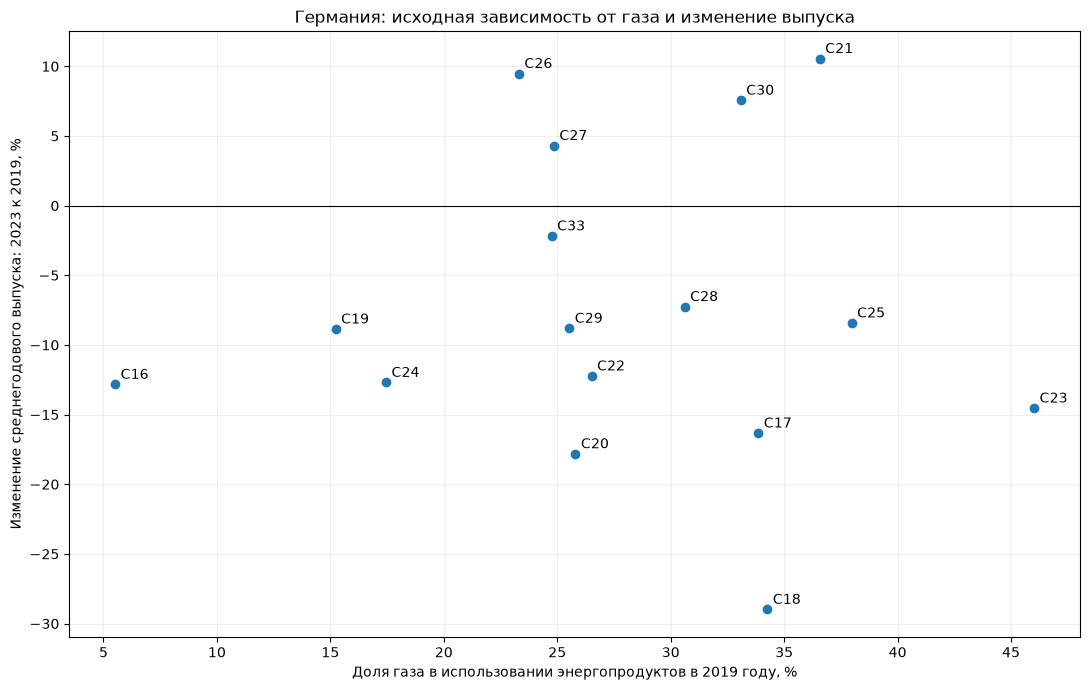

In [24]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(
    comparison["gas_share_pct"],
    comparison["output_change_pct"],
)

for row in comparison.itertuples():
    ax.annotate(
        row.nace_r2,
        (row.gas_share_pct, row.output_change_pct),
        xytext=(4, 4),
        textcoords="offset points",
    )

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xlabel("Доля газа в использовании энергопродуктов в 2019 году, %")
ax.set_ylabel("Изменение среднегодового выпуска: 2023 к 2019, %")
ax.set_title("Германия: исходная зависимость от газа и изменение выпуска")
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

In [25]:
fig.savefig(
    "../figure/gas_exposure_vs_output_change.png",
    dpi=300,
    bbox_inches="tight",
)

comparison.to_csv(
    "../data/processed/comparison_2019_2023.csv",
    index=False,
)